<a href="https://colab.research.google.com/github/guillermops2392/ds3guillermo/blob/main/entrega_3_Guillermo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# @title
import pandas as pd
from pathlib import Path

# Cambiá a "bbc_news" si preferís artículos largos.
DATASET = "ag_news"            # opciones: "ag_news" | "bbc_news"
BASE = Path(r"/content/ag_news").parent   # carpeta donde está este script


def cargar(dataset: str = DATASET):
    """Devuelve (train_df, test_df) con columnas: text, label."""
    tr = pd.read_csv(BASE / dataset / f"{dataset}_train.csv")
    te = pd.read_csv(BASE / dataset / f"{dataset}_test.csv")
    return tr, te


if __name__ == "__main__":
    train_df, test_df = cargar()
    print(f"Dataset: {DATASET}")
    print(f"Train: {train_df.shape} | Test: {test_df.shape}")
    print("Clases:", sorted(train_df['label'].unique()))
    print(train_df.head())

Dataset: ag_news
Train: (8000, 2) | Test: (2000, 2)
Clases: ['Business', 'Sci_Tech', 'Sports', 'World']
                                                text     label
0  Red Hat Appoints New CFO. September 2, 2004 --...  Sci_Tech
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...  Sci_Tech
2  Radio Outage Grounds West Coast Flights. Airpo...  Business
3  Hollywood lawsuits to strike Net pirates. Holl...  Sci_Tech
4  Custis Takes Control. Family and Tony Robbins ...    Sports


In [4]:
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Descargar stopwords en caso de que no estén disponibles
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

def limpiar_texto(texto):
    """Limpia y normaliza el texto quitando caracteres especiales y stopwords."""
    if not isinstance(texto, str):
        return ""
    # Minúsculas
    texto = texto.lower()
    # Eliminar caracteres especiales y números
    texto = re.sub(r'[^a-z\s]', ' ', texto)
    # Eliminar espacios múltiples y stopwords
    tokens = [word for word in texto.split() if word not in stop_words]
    return " ".join(tokens)

# 1. Preprocesamiento de los datos
train_df['clean_text'] = train_df['text'].apply(limpiar_texto)
test_df['clean_text'] = test_df['text'].apply(limpiar_texto)

X_train, y_train = train_df['clean_text'], train_df['label']
X_test, y_test = test_df['clean_text'], test_df['label']

# 2. Vectorización con TF-IDF (Evitando Data Leakage)
# Usamos n-gramas (unigramas y bigramas) y limitamos las características máximas
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

# Ajustamos y transformamos SOLO sobre el set de entrenamiento
X_train_tfidf = vectorizer.fit_transform(X_train)
# Transformamos el set de test con el vocabulario ya aprendido
X_test_tfidf = vectorizer.transform(X_test)

print(f"Dimensiones de la matriz de entrenamiento: {X_train_tfidf.shape}")
print(f"Dimensiones de la matriz de evaluación: {X_test_tfidf.shape}")

Dimensiones de la matriz de entrenamiento: (8000, 5000)
Dimensiones de la matriz de evaluación: (2000, 5000)


=== REPORTE DE CLASIFICACIÓN: MULTINOMIAL NAIVE BAYES ===
              precision    recall  f1-score   support

    Business       0.85      0.84      0.85       500
    Sci_Tech       0.86      0.87      0.86       500
      Sports       0.95      0.96      0.96       500
       World       0.90      0.89      0.90       500

    accuracy                           0.89      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.89      0.89      0.89      2000


=== REPORTE DE CLASIFICACIÓN: REGRESIÓN LOGÍSTICA ===
              precision    recall  f1-score   support

    Business       0.85      0.86      0.85       500
    Sci_Tech       0.86      0.87      0.87       500
      Sports       0.95      0.96      0.95       500
       World       0.91      0.89      0.90       500

    accuracy                           0.89      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.89      0.89      0.89      2000



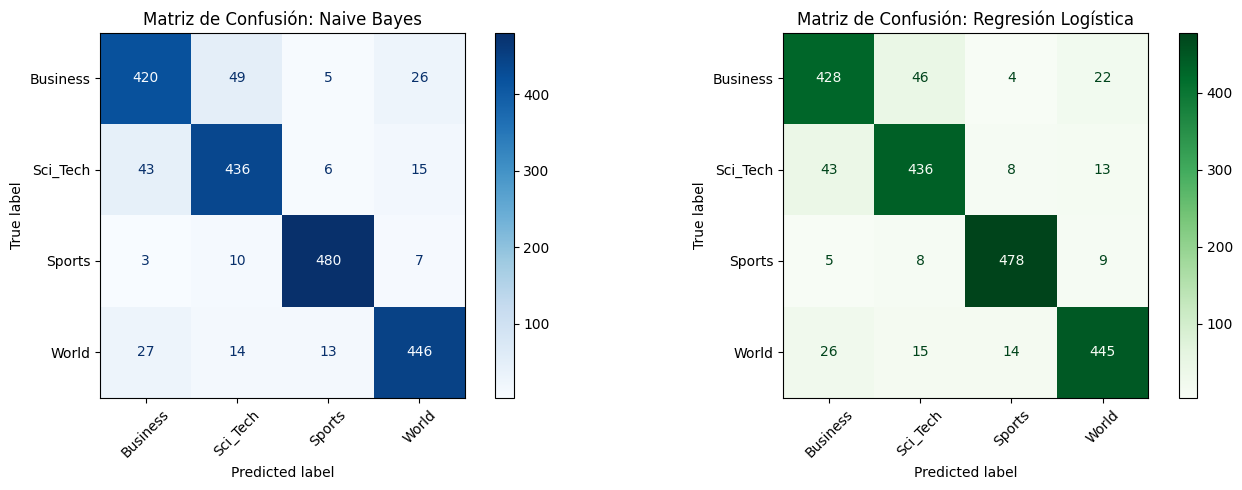

In [5]:
# 3. Modelado y Entrenamiento
# Entrenamos Naive Bayes como baseline robusto y rápido
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_preds = nb_model.predict(X_test_tfidf)

# Entrenamos Regresión Logística, excelente para representación lineal en alta dimensión (TF-IDF)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)
lr_preds = lr_model.predict(X_test_tfidf)

# 4. Evaluación de Modelos
print("=== REPORTE DE CLASIFICACIÓN: MULTINOMIAL NAIVE BAYES ===")
print(classification_report(y_test, nb_preds))

print("\n=== REPORTE DE CLASIFICACIÓN: REGRESIÓN LOGÍSTICA ===")
print(classification_report(y_test, lr_preds))

# Graficar matrices de confusión comparativas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, nb_preds,
    ax=axes[0],
    cmap='Blues',
    xticks_rotation=45
)
axes[0].set_title('Matriz de Confusión: Naive Bayes')

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_preds,
    ax=axes[1],
    cmap='Greens',
    xticks_rotation=45
)
axes[1].set_title('Matriz de Confusión: Regresión Logística')

plt.tight_layout()
plt.show()